In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error, structural_similarity

# Преобразование Хаара: 3 ступени сжатия

Размер изображения: (512, 512)


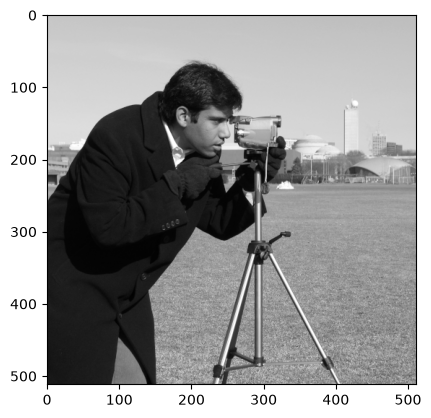

In [2]:
# Изображение camera из набора skimage.data, размер 512x512.
image = cv2.imread('camera.png', cv2.IMREAD_GRAYSCALE)
image_float = image.astype(np.float64)
print('Размер изображения:', image.shape)
plt.imshow(image, cmap='gray')
plt.show()

# 1. Прямое преобразование

In [3]:
def haar_step(block):
    # Сначала суммы и разности соседних столбцов, затем строк.
    scale = np.sqrt(2)
    low = (block[:, 0::2] + block[:, 1::2]) / scale
    high = (block[:, 0::2] - block[:, 1::2]) / scale
    rows = np.concatenate((low, high), axis=1)
    low = (rows[0::2, :] + rows[1::2, :]) / scale
    high = (rows[0::2, :] - rows[1::2, :]) / scale
    return np.concatenate((low, high), axis=0)


def haar_transform(img, levels):
    result = img.astype(np.float64).copy()
    h, w = result.shape
    for level in range(levels):
        height, width = h // 2**level, w // 2**level
        result[:height, :width] = haar_step(result[:height, :width])
    return result

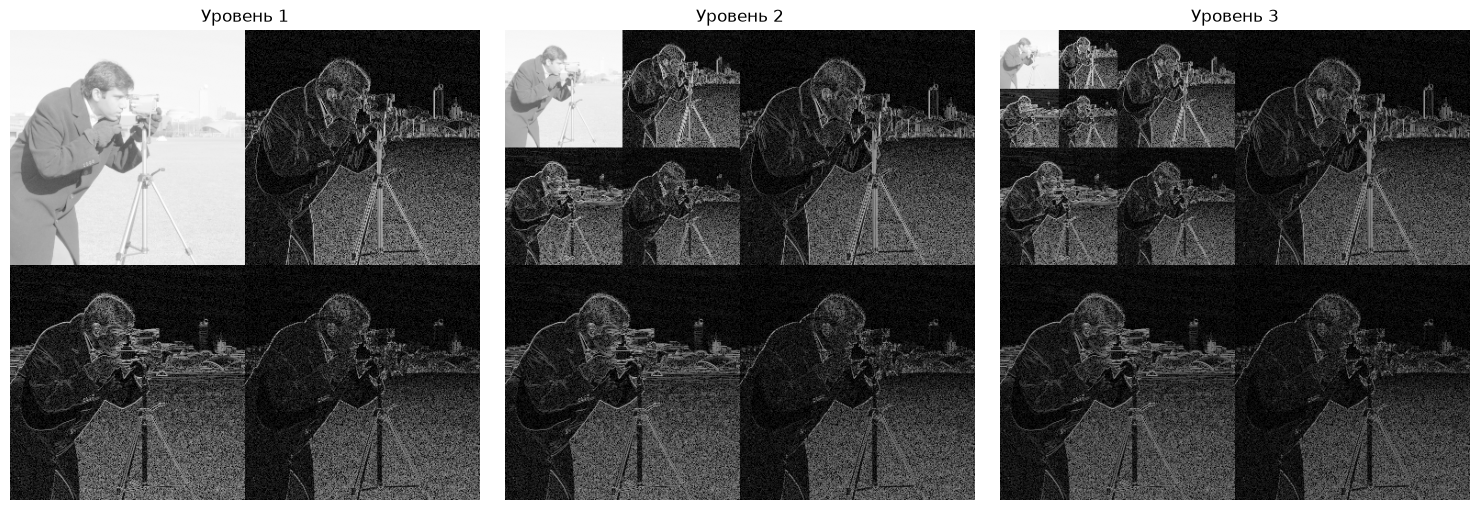

In [4]:
coefficients = [haar_transform(image_float, level) for level in (1, 2, 3)]

plt.figure(figsize=(15, 5))
for i, coeffs in enumerate(coefficients, 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.log1p(np.abs(coeffs)), cmap='gray')
    plt.title('Уровень %d' % i)
    plt.axis('off')
plt.tight_layout()
plt.show()

Уровень 1: размер LL = 256x256
Уровень 2: размер LL = 128x128
Уровень 3: размер LL = 64x64


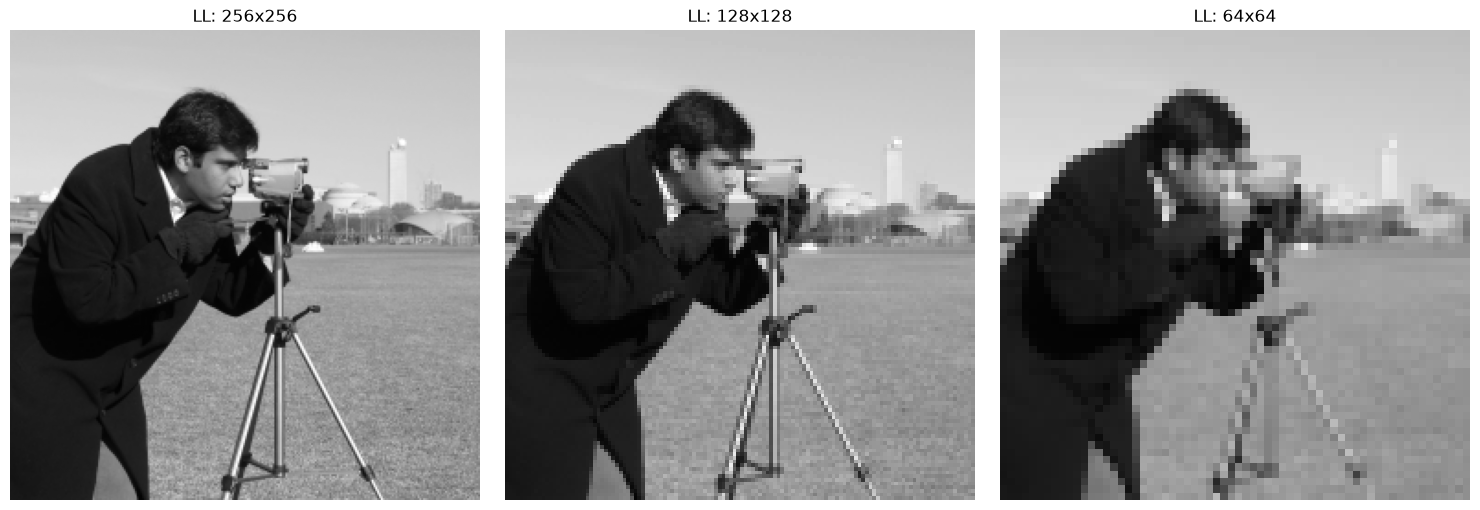

In [5]:
# На следующем уровне преобразуется только верхний левый блок LL.
plt.figure(figsize=(15, 5))
for level, coeffs in enumerate(coefficients, 1):
    size = image.shape[0] // 2**level
    approximation = coeffs[:size, :size] / 2**level
    print('Уровень %d: размер LL = %dx%d' % (level, size, size))
    plt.subplot(1, 3, level)
    plt.imshow(approximation, cmap='gray', vmin=0, vmax=255)
    plt.title('LL: %dx%d' % (size, size))
    plt.axis('off')
plt.tight_layout()
plt.show()

# 2. Обратное преобразование

In [6]:
def inverse_haar_step(block):
    h, w = block.shape
    scale = np.sqrt(2)
    rows = np.empty_like(block)
    rows[0::2, :] = (block[:h // 2, :] + block[h // 2:, :]) / scale
    rows[1::2, :] = (block[:h // 2, :] - block[h // 2:, :]) / scale
    result = np.empty_like(block)
    result[:, 0::2] = (rows[:, :w // 2] + rows[:, w // 2:]) / scale
    result[:, 1::2] = (rows[:, :w // 2] - rows[:, w // 2:]) / scale
    return result


def inverse_haar(coeffs, levels):
    result = coeffs.copy()
    h, w = result.shape
    for level in range(levels - 1, -1, -1):
        height, width = h // 2**level, w // 2**level
        result[:height, :width] = inverse_haar_step(result[:height, :width])
    return result

Ошибка восстановления: 3.694822225952521e-13


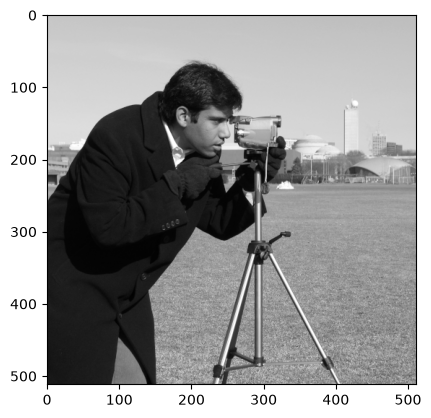

In [7]:
restored = inverse_haar(coefficients[2], 3)
print('Ошибка восстановления:', np.max(np.abs(image_float - restored)))
plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
plt.show()

# 3. Сжатие
Оставляю блок LL, остальные коэффициенты обнуляю.

In [8]:
restored_images = []
for level, coeffs in enumerate(coefficients, 1):
    size = image.shape[0] // 2**level
    compressed_coeffs = np.zeros_like(coeffs)
    compressed_coeffs[:size, :size] = coeffs[:size, :size]
    reconstructed = inverse_haar(compressed_coeffs, level)
    restored_images.append(reconstructed)

    mse = mean_squared_error(image_float, reconstructed)
    ssim = structural_similarity(image_float, reconstructed, data_range=255)
    print('Уровень %d: MSE = %.2f, SSIM = %.4f' % (level, mse, ssim))

Уровень 1: MSE = 88.00, SSIM = 0.8747
Уровень 2: MSE = 197.84, SSIM = 0.7506
Уровень 3: MSE = 374.54, SSIM = 0.6316


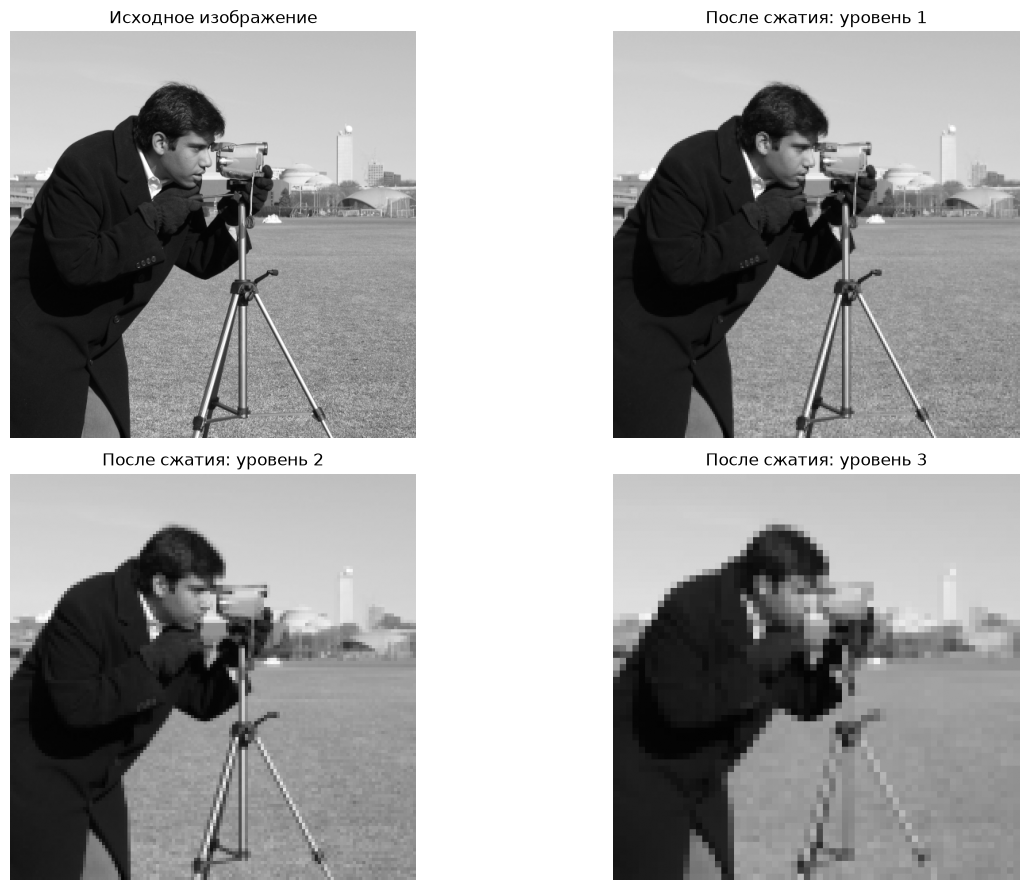

In [9]:
plt.figure(figsize=(14, 9))
plt.subplot(2, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.axis('off')
for level, reconstructed in enumerate(restored_images, 1):
    plt.subplot(2, 2, level + 1)
    plt.imshow(reconstructed, cmap='gray', vmin=0, vmax=255)
    plt.title('После сжатия: уровень %d' % level)
    plt.axis('off')
plt.tight_layout()
plt.show()